# Lab 00 — Python data toolkit and exploratory data analysis

*Meet a table, examine it, and write down what the model must be told*

**Goal.** Use NumPy, pandas and Matplotlib to examine a real table before modelling it: take its first measurements, catch the values that cannot be true, study each column alone and against the target, compare columns with each other, and turn what you find into a first model that is scored honestly.

**Data.** `all_datasets/supervised/heart_disease/heart_disease.csv` with its data card `README.md`

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab00_data_toolkit_eda/lab00_data_toolkit_eda_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab00_data_toolkit_eda/lab00_data_toolkit_eda_worked.py`.

**Evidence.** `results/lab00/` — the column overview, the cleaning log, five-number summaries, disease rates by category, the cholesterol correlations, the model comparison, the test metrics and the exploration log

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Load the table, take its first measurements, and catch the values that cannot be true | 2–5 |
| B | Seal a test set, then study one column at a time: shape, five numbers, fences, counts | 6–9 |
| C | Compare each column, and each gap, with the target | 10–12 |
| D | Compare columns with each other, and watch a correlation change sign | 13–14 |
| E | Turn the findings into baselines, a pipeline and one honest test score | 15–17 |
| Finish | Save the evidence; then examine women and men separately yourself | 18–20 |
| After | Your-turn tasks, expected findings, troubleshooting and the checklist (on the lab sheet) | — |

## Setup

### Question 1 — Setup

Run this first, and keep this kernel for the later questions. Every lab starts the same way: the course helper, the libraries, and the three folders the lab uses.

**Read the code.**

- `sys.path.insert(0, "..")` lets Python import `course_setup.py` from the folder above this lab's own.
- `import numpy as np` and `import pandas as pd` give the two libraries the short names used throughout the book.
- Each `from sklearn...` line pulls in one tool by name. Every tool is explained at the question that first uses it.
- `start_lab("lab00")` returns three folders: `DATA` to read from, and `RESULTS` and `MODELS` to write to.

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab

# 2. The libraries this lab uses.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer                      # different steps per kind of column
from sklearn.impute import SimpleImputer                           # fill missing values
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline                              # chain preparation and model together
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 3. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab00")

course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab00/ and models/


## Part A — First contact with a table

**Goal.** Load the heart table, learn what every column means, and find the values that no patient could have.

*Questions 2–5 · Data: heart disease and its data card*

### Question 2 — Read the data card, then the table

A professional reads the data dictionary before the data. The data card, the `README.md` beside the file, says what each column means and in which units. The cell prints the card's column meanings, loads the table, and shows its size and its first three patients.

**Read the code.**

- `read_text()` loads the card as one long string. The loop walks through the lines of its column table and splits each line on `" | "` to pick out the column's name and meaning.
- `pd.read_csv(...)` reads the file into a DataFrame. `DATA / "supervised/..."` joins folder names in a way that works on every operating system.
- `heart.shape` is the pair (rows, columns).
- `heart.head(3)` is the first three rows. `.T` turns the result on its side, so each column of the table becomes a line and nothing is cut off.

In [2]:
# The data card beside the data says what each column means. Its column table starts at "| `Age`".
card = (DATA / "supervised/heart_disease/README.md").read_text(encoding="utf-8")
for row in card[card.index("| `Age`"):].splitlines():
    column, meaning = row.split(" | ")[:2]
    print(f"{column.strip('| `'):16s}{meaning}")

# The table itself: one row per patient.
heart = pd.read_csv(DATA / "supervised/heart_disease/heart_disease.csv")
print("\nshape:", heart.shape)
print(heart.head(3).T)

Age             age in years
Sex             `M` or `F`
ChestPainType   `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` no chest pain
RestingBP       resting blood pressure in mm Hg; 0 means not measured
Cholesterol     serum cholesterol in mg/dl; 0 means not measured
FastingBS       1 if fasting blood sugar is above 120 mg/dl
RestingECG      resting electrocardiogram: `Normal`, `ST` (ST-T wave abnormality) or `LVH` (thickened left ventricle)
MaxHR           highest heart rate reached in the exercise test, beats per minute
ExerciseAngina  chest pain brought on by exercise: `Y` or `N`
Oldpeak         how far the ST segment of the ECG drops during exercise, in mm
ST_Slope        slope of the ST segment at peak exercise: `Up`, `Flat` or `Down`
HeartDisease    1 if diagnosed with heart disease: the label

shape: (918, 12)
                     0       1    2
Age                 40      49   37
Sex                  M       F    M
ChestPainType      ATA     NAP  ATA


**What the output shows.** 918 patients, one per row, and 12 columns. Patient 0 is a 40-year-old man with atypical angina, a blood pressure of 140, a cholesterol of 289 and a top heart rate of 172, and he does not have heart disease. Read the card's lines for `RestingBP` and `Cholesterol` once more before the next question: they say what a zero means.

### Question 3 — Types, blanks, repeats and distinct values

Take three quick measurements of every column: its type, how many of its cells are blank, and how many different values it holds. The last one decides how a column is treated. A column with two to four distinct values is a category, even when it is stored as a number.

**Read the code.**

- A DataFrame can be built from a dictionary: each key becomes a column name and each value a column. `heart.dtypes`, `heart.isna().sum()` and `heart.nunique()` each give one entry per column of `heart`, so they line up as three columns of the overview.
- `isna()` gives `True` for a blank cell, and `.sum()` counts the `True`s in each column.
- `duplicated()` marks a row that repeats an earlier row exactly.
- The two list comprehensions sort the column names into `categories` (four distinct values or fewer) and `numbers` (the rest), leaving out the target. Every later question reuses these two lists.
- `heart[target].mean()` is the share of ones in a column of zeros and ones.

In [3]:
# One line per column: its type, how many cells are blank, and how many different values it takes.
overview = pd.DataFrame({
    "type": heart.dtypes.astype(str),
    "blank": heart.isna().sum(),
    "distinct": heart.nunique(),
})
print(overview)
print("\nrepeated rows:", heart.duplicated().sum())

# A column with only a few distinct values is a category, whatever its type says.
target = "HeartDisease"
categories = [c for c in heart.columns if heart[c].nunique() <= 4 and c != target]
numbers = [c for c in heart.columns if c not in categories and c != target]
print("numbers:   ", numbers)
print("categories:", categories)
print("share with heart disease:", round(heart[target].mean(), 3))

                   type  blank  distinct
Age               int64      0        50
Sex              object      0         2
ChestPainType    object      0         4
RestingBP         int64      0        67
Cholesterol       int64      0       222
FastingBS         int64      0         2
RestingECG       object      0         3
MaxHR             int64      0       119
ExerciseAngina   object      0         2
Oldpeak         float64      0        53
ST_Slope         object      0         3
HeartDisease      int64      0         2

repeated rows: 0
numbers:    ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
categories: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
share with heart disease: 0.553


**What the output shows.** No blank cells and no repeated rows. Five columns are numbers and six are categories: `FastingBS` is stored as an integer but takes only the values 0 and 1, so it joins the categories. 55.3% of the patients have heart disease. The two classes are close to balanced, and always guessing *disease* would already be 55.3% accurate.

### Question 4 — Could every value be real?

A table with no blanks can still have missing values. Print the smallest, the middle and the largest value of each number column, and ask of each one: could a living patient have this value?

**Read the code.**

- `describe()` summarizes every number column, and `.loc[["min", "50%", "max"]]` keeps three of its rows. `"50%"` is the median.
- `heart["RestingBP"] == 0` compares every row with 0 and gives a column of `True` and `False`: a mask.
- The `.sum()` of a mask counts the rows where it is `True`, and its `.mean()` is their share. The format `:.1%` prints a share as a percentage with one decimal.
- `heart.loc[no_pressure, [...]]` selects rows with the mask and columns with a list of names.

In [4]:
# The smallest, middle and largest value of every number column.
print(heart[numbers].describe().loc[["min", "50%", "max"]].round(1))

# A comparison gives one True or False per row: a mask.
# The sum of a mask counts the rows; inside loc[] a mask selects them.
no_pressure = heart["RestingBP"] == 0
no_cholesterol = heart["Cholesterol"] == 0
print("\nblood pressure of 0:", no_pressure.sum(), "  cholesterol of 0:", no_cholesterol.sum(),
      f"({no_cholesterol.mean():.1%} of the patients)",
      "  negative Oldpeak:", (heart["Oldpeak"] < 0).sum())
print(heart.loc[no_pressure, ["Age", "Sex", "RestingBP", "Cholesterol", "MaxHR", "HeartDisease"]])

      Age  RestingBP  Cholesterol  MaxHR  Oldpeak
min  28.0        0.0          0.0   60.0     -2.6
50%  54.0      130.0        223.0  138.0      0.6
max  77.0      200.0        603.0  202.0      6.2

blood pressure of 0: 1   cholesterol of 0: 172 (18.7% of the patients)   negative Oldpeak: 13
     Age Sex  RestingBP  Cholesterol  MaxHR  HeartDisease
449   55   M          0            0    155             1


**What the output shows.** The minimum of `RestingBP` and of `Cholesterol` is 0, which no living person has. One patient has a blood pressure of 0, and 172 patients, 18.7% of the table, have a cholesterol of 0. The data card says what this means: the value was not measured. The single patient with no blood pressure, row 449, has no cholesterol reading either. `Oldpeak` is negative for 13 patients. The card does not call that impossible, so those values stay.

### Question 5 — See the zeros, then mark them as missing

Draw the suspicious column, repair it, and write down what you did. The repair replaces each impossible zero with `NaN`, the marker pandas uses for a missing value. It is a fixed rule that comes from the meaning of the column, not from any statistic of the data, so it may run before the table is split. No row is dropped.

**Read the code.**

- `raw = heart.copy()` keeps an untouched copy, because the next lines change `heart` itself. Later questions compare the two.
- `replace(0, np.nan)` swaps every 0 in the column for a missing value, and assigning the result back to `heart[column]` stores it.
- `plt.subplots(1, 2, sharey=True)` makes one row of two charts with a shared vertical scale. `bins=np.arange(0, 651, 25)` cuts cholesterol into bands 25 mg/dl wide.
- `dropna()` leaves the missing values out of the second histogram.
- The `cleaning_log` dictionary records each rule and how many cells it touched.
- `blanks[blanks > 0]` is a mask again, this time on a column of counts: it keeps the columns that now have blanks.

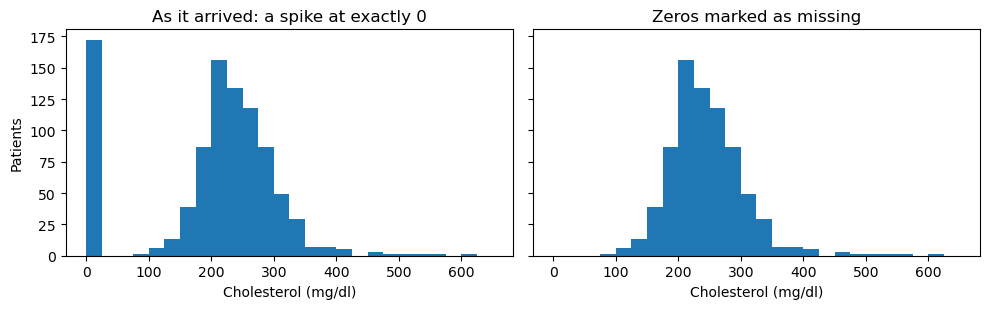

{'rows': 918, 'RestingBP zeros marked missing': 1, 'Cholesterol zeros marked missing': 172, 'rows dropped': 0}
blank cells now: {'RestingBP': 1, 'Cholesterol': 172}


In [5]:
raw = heart.copy()                           # the table as it arrived, kept for comparison

# The repair is a fixed rule from the data card, so it may run before any split.
# NaN is the marker for "missing".
for column in ["RestingBP", "Cholesterol"]:
    heart[column] = heart[column].replace(0, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
axes[0].hist(raw["Cholesterol"], bins=np.arange(0, 651, 25))
axes[0].set_title("As it arrived: a spike at exactly 0")
axes[1].hist(heart["Cholesterol"].dropna(), bins=np.arange(0, 651, 25))
axes[1].set_title("Zeros marked as missing")
for ax in axes:
    ax.set_xlabel("Cholesterol (mg/dl)")
axes[0].set_ylabel("Patients")
plt.tight_layout()
plt.savefig(RESULTS / "cholesterol_before_and_after.png", dpi=160, bbox_inches="tight")
plt.show()

cleaning_log = {
    "rows": len(heart),
    "RestingBP zeros marked missing": int(no_pressure.sum()),
    "Cholesterol zeros marked missing": int(no_cholesterol.sum()),
    "rows dropped": 0,
}
print(cleaning_log)
blanks = heart.isna().sum()
print("blank cells now:", blanks[blanks > 0].to_dict())

**What the output shows.** The left chart has a bar of 172 patients standing alone at 0, far from everyone else. The right chart is the same column without them: one hump with a tail to the right. The table now has 173 blank cells, 1 in `RestingBP` and 172 in `Cholesterol`, and still has 918 rows. From here on pandas leaves the blanks out of every mean and histogram, and the pipeline of Part E decides how to fill them.

<!-- figure: cholesterol_before_and_after.png | Reference plot from the supplied notebook | 4.6cm -->

**Checkpoint: before you move on**

- 918 patients and 12 columns: five numbers, six categories and the target. 55.3% have heart disease.
- The table had no blank cells, yet 173 values were missing: 172 cholesterol readings and 1 blood pressure were stored as 0.
- You can say why this repair may run before the split, and why no row was dropped.

## Part B — One column at a time

**Goal.** Set the test patients aside, then describe each column of the training patients: its shape, its five numbers, its extremes and its counts.

*Questions 6–9 · Data: the 734 training patients*

### Question 6 — Seal a test set

Everything so far asked what the columns are. The rest of the lab asks how they relate to the answer, and those relationships are what a model learns. Set a fifth of the patients aside now, and do not look at them again until Question 17. If you study relationships on every row, your choices will have seen the test rows, and the final score will flatter them.

**Read the code.**

- `train_test_split` shuffles the rows and cuts them in two. `test_size=0.2` puts 20% of them in the test set.
- `stratify=heart[target]` keeps the share of heart disease the same in both parts, and `random_state=42` fixes the shuffle, so everyone gets the same split.
- `raw.loc[train.index]` picks the same training patients out of the untouched copy. `train.index` holds their row labels.

In [6]:
# stratify keeps the share of heart disease equal on both sides; random_state makes the split repeatable.
train, test = train_test_split(heart, test_size=0.2, random_state=42, stratify=heart[target])
raw_train = raw.loc[train.index]             # the same training patients, with the zeros still in
print("training patients:", len(train), "  test patients:", len(test))
print("share with heart disease: training", round(train[target].mean(), 3),
      "  test", round(test[target].mean(), 3))

training patients: 734   test patients: 184
share with heart disease: training 0.553   test 0.554


**What the output shows.** 734 patients to learn from and 184 sealed away, with the same disease rate on both sides, 55.3% and 55.4%. Every number from here to Question 16 is computed on the 734.

### Question 7 — The shape of each number column

A summary compresses a column into a few numbers, and a histogram shows all of it. Draw the five number columns, and print the mean, the median and the skewness of each. Skewness is 0 for a symmetric column, positive when the long tail points right and negative when it points left.

**Read the code.**

- `plt.subplots(1, 5)` returns five charts, and `zip(axes, numbers)` pairs each chart with a column name, so one loop draws all five.
- The `f"..."` string builds each title, and `{train[column].skew():.2f}` prints the skewness with two decimals.
- `describe().loc[[...]].T` keeps three rows of the summary and turns them on their side, one line per feature. `count` is the number of values that are not missing.
- The next lines recompute cholesterol on `raw_train`, the same patients with the zeros still in.
- `train["RestingBP"] % 10 == 0` is a mask for readings that are a multiple of 10: `%` gives the remainder of a division.

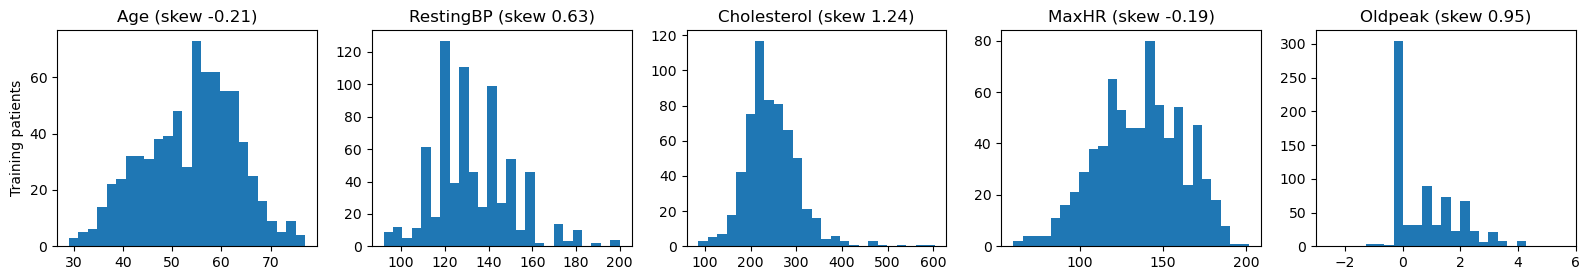

             count    mean    50%  skew
Age          734.0   53.85   55.0 -0.21
RestingBP    734.0  132.87  130.0  0.63
Cholesterol  605.0  246.56  238.0  1.24
MaxHR        734.0  136.38  138.0 -0.19
Oldpeak      734.0    0.87    0.5  0.95

cholesterol with the zeros left in: mean 203.2  skew -0.64
share of Oldpeak that is exactly 0: 0.414
share of blood pressures that are a multiple of 10: 0.642


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 2.9))
for ax, column in zip(axes, numbers):
    ax.hist(train[column].dropna(), bins=25)
    ax.set_title(f"{column} (skew {train[column].skew():.2f})")
axes[0].set_ylabel("Training patients")
plt.tight_layout()
plt.savefig(RESULTS / "the_shape_of_each_number_column.png", dpi=160, bbox_inches="tight")
plt.show()

shape_table = train[numbers].describe().loc[["count", "mean", "50%"]].T
shape_table["skew"] = train[numbers].skew()
print(shape_table.round(2))
print("\ncholesterol with the zeros left in: mean", round(raw_train["Cholesterol"].mean(), 1),
      " skew", round(raw_train["Cholesterol"].skew(), 2))
print("share of Oldpeak that is exactly 0:", round((train["Oldpeak"] == 0).mean(), 3))
round_readings = (train["RestingBP"] % 10 == 0).mean()
print("share of blood pressures that are a multiple of 10:", round(round_readings, 3))

**What the output shows.** `Age` and `MaxHR` are close to symmetric. Cholesterol has 605 values, a mean of 246.56 and a skew of 1.24. With the zeros left in, the same column had a mean of 203.2 and a skew of −0.64: the repair moved the mean by 43 mg/dl and reversed the direction of the tail. `Oldpeak` is a pile and a tail, with 41.4% of its values exactly 0. `RestingBP` shows tall thin spikes, because 64.2% of the readings are a multiple of 10. Blood pressures are not really that tidy: someone read a gauge by eye and rounded. A histogram shows how a column was measured as well as what was measured.

<!-- figure: the_shape_of_each_number_column.png | Reference plot from the supplied notebook | 3.1cm -->

### Question 8 — Five numbers, fences and box plots

Five numbers describe a column without assuming any shape: the minimum, the first quartile Q1, the median, the third quartile Q3 and the maximum. A box plot draws them. Its fences sit one and a half box-lengths beyond the box, its whiskers stop at the last value inside each fence, and every value beyond a fence is drawn as a dot. Compute all of this for each column, then compare with the rival rule that flags values more than three standard deviations from the mean.

**Read the code.**

- `quantile([0.25, 0.50, 0.75])` returns the three quartiles at once, and the three names on the left unpack them.
- `(values < low_fence) | (values > high_fence)` joins two masks with `|`, which means "or". Each mask needs its own parentheses.
- The function returns a `pd.Series` with named entries. That lets `train[numbers].apply(five_numbers)` build a table by calling the function once per column, and `.T` puts one feature on each line.
- `z` rewrites every value as a number of standard deviations from its column's mean. It uses broadcasting: a table minus a row of means. `z.abs() > 3` is then a table of masks, and `.sum()` counts per column.
- `ax.boxplot(..., vert=False)` draws a horizontal box plot. It needs the missing values dropped first.

              min     Q1  median     Q3    max  low fence  high fence  outside
Age          29.0   47.0    55.0   61.0   77.0      26.00       82.00      0.0
RestingBP    92.0  120.0   130.0  141.0  200.0      88.50      172.50     20.0
Cholesterol  85.0  210.0   238.0  277.0  603.0     109.50      377.50     20.0
MaxHR        60.0  119.0   138.0  156.0  202.0      63.50      211.50      2.0
Oldpeak      -2.6    0.0     0.5    1.5    5.6      -2.25        3.75     13.0

beyond 3 standard deviations: {'Age': 0, 'RestingBP': 6, 'Cholesterol': 7, 'MaxHR': 0, 'Oldpeak': 6}


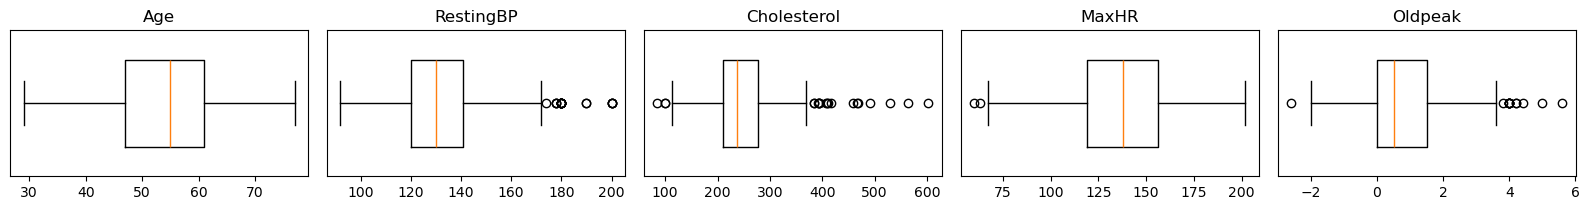

In [8]:
def five_numbers(values):
    """The five-number summary, the fences 1.5 IQR beyond the box, and how many values lie outside them."""
    values = values.dropna()
    q1, median, q3 = values.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outside = ((values < low_fence) | (values > high_fence)).sum()
    return pd.Series({"min": values.min(), "Q1": q1, "median": median, "Q3": q3, "max": values.max(),
                      "low fence": low_fence, "high fence": high_fence, "outside": outside})

summaries = train[numbers].apply(five_numbers).T
print(summaries)

# The rival rule: more than 3 standard deviations from the mean.
z = (train[numbers] - train[numbers].mean()) / train[numbers].std()
print("\nbeyond 3 standard deviations:", (z.abs() > 3).sum().to_dict())

fig, axes = plt.subplots(1, 5, figsize=(16, 2.2))
for ax, column in zip(axes, numbers):
    ax.boxplot(train[column].dropna(), vert=False, widths=0.6)
    ax.set_yticks([])
    ax.set_title(column)
plt.tight_layout()
plt.savefig(RESULTS / "box_plots_of_the_number_columns.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** For cholesterol, Q1 is 210, the median 238 and Q3 277, so the box is 67 wide and the fences sit at 109.5 and 377.5. Twenty readings lie outside them. The fence rule flags 20 blood pressures, 20 cholesterol readings, 2 heart rates and 13 `Oldpeak` values, while the three-standard-deviation rule flags 6, 7, 0 and 6. The two rules disagree because the mean and the standard deviation are themselves pulled by the extreme values they are meant to judge. None of these values is impossible, so none is removed. A cholesterol of 603 is a patient, and probably one the model matters for.

<!-- figure: box_plots_of_the_number_columns.png | Reference plot from the supplied notebook | 2.5cm -->

### Question 9 — Count the categories

For a category the summary is a count per value. Two questions matter. Is any value spelled two ways? And is any value so rare that a rate computed from it will be mostly luck?

**Read the code.**

- `value_counts()` counts how often each value occurs, the most frequent first, and `.plot.bar(ax=ax)` draws those counts on the chart you pass in.
- `to_dict()` turns the counts into `{value: count}`, so that each column fits on one printed line.
- The `min(...)` line builds one tuple per category column, holding the size of its smallest group, the column and the value, and keeps the smallest tuple. Tuples compare by their first entry.

Sex             {'M': 579, 'F': 155}
ChestPainType   {'ASY': 403, 'NAP': 155, 'ATA': 136, 'TA': 40}
FastingBS       {0: 566, 1: 168}
RestingECG      {'Normal': 447, 'LVH': 146, 'ST': 141}
ExerciseAngina  {'N': 434, 'Y': 300}
ST_Slope        {'Flat': 374, 'Up': 313, 'Down': 47}


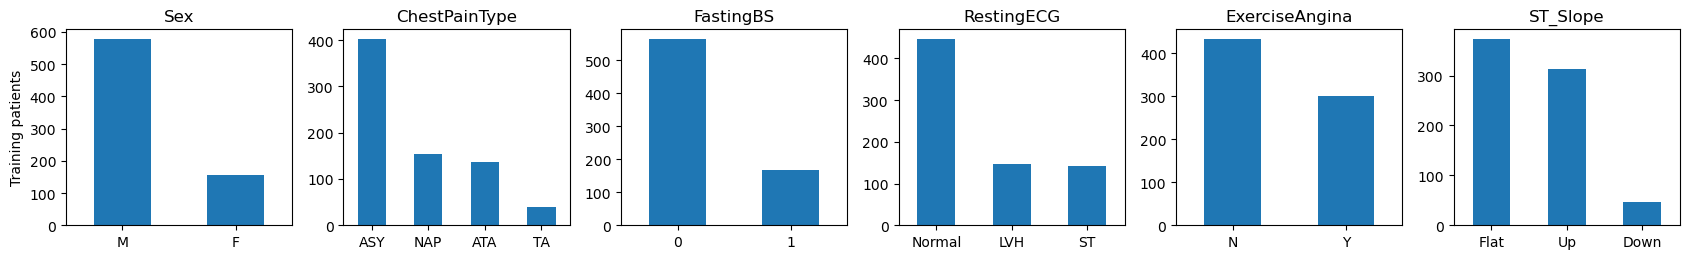


smallest group: TA in ChestPainType, 40 patients (5.4%)


In [9]:
fig, axes = plt.subplots(1, 6, figsize=(17, 2.7))
for ax, column in zip(axes, categories):
    counts = train[column].value_counts()
    counts.plot.bar(ax=ax, rot=0)
    ax.set_title(column)
    ax.set_xlabel("")
    print(f"{column:15s}", counts.to_dict())
axes[0].set_ylabel("Training patients")
plt.tight_layout()
plt.savefig(RESULTS / "how_often_each_category_occurs.png", dpi=160, bbox_inches="tight")
plt.show()

smallest = min((train[c].value_counts().min(), c, train[c].value_counts().idxmin()) for c in categories)
size, column, value = smallest
print(f"\nsmallest group: {value} in {column}, {size} patients ({size / len(train):.1%})")

**What the output shows.** No category is spelled two ways. Men are 579 of the 734 patients, 79%. Chest pain is `ASY`, no pain, for 403 patients, more than half. The smallest group anywhere is typical angina, `TA`, with 40 patients, 5.4% of the table, and `Down` in `ST_Slope` has 47. Remember those two groups at Question 11.

<!-- figure: how_often_each_category_occurs.png | Reference plot from the supplied notebook | 2.7cm -->

**Checkpoint: before you move on**

- 734 training patients and 184 test patients, both with about 55% heart disease.
- Marking the zeros as missing moved the mean cholesterol from 203.2 to 246.6 and its skew from −0.64 to 1.24.
- The cholesterol fences are 109.5 and 377.5, and 20 readings lie outside them. You can say why they stay in the table.
- The smallest category, typical angina, has 40 patients.

## Part C — Each column against the target

**Goal.** Find out which columns, and which gaps, change what you expect of the answer, and how far each finding can be trusted.

*Questions 10–12 · Data: the 734 training patients*

### Question 10 — Numbers against the target

Now ask whether a column tells you anything about the answer. Split the patients by the target and compare each number column in the two groups, first by its mean and then on a chart, because two groups with different means can still overlap almost completely.

**Read the code.**

- `train.groupby(target)[numbers].mean()` splits the patients into those without heart disease (0) and with it (1), and averages each number column inside each group.
- The inner loop draws two histograms on the same chart. `alpha=0.6` makes the bars see-through, so the overlap is visible, and `label=` names each group for the legend.
- `train.loc[low, target].mean()` is the pattern "the rate of the target among the rows that pass a test". You will write it many times.

                Age  RestingBP  Cholesterol   MaxHR  Oldpeak
HeartDisease                                                
0             51.28     130.82       241.91  148.07     0.42
1             55.92     134.53       251.61  126.93     1.22


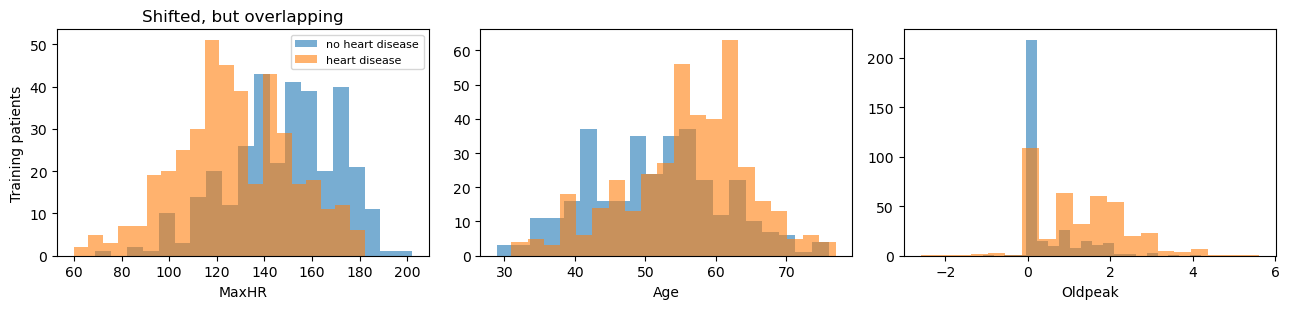


disease rate when the highest heart rate is under 120: 0.793  at 150 or more: 0.322


In [10]:
print(train.groupby(target)[numbers].mean().round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, column in zip(axes, ["MaxHR", "Age", "Oldpeak"]):
    for label, name in [(0, "no heart disease"), (1, "heart disease")]:
        ax.hist(train.loc[train[target] == label, column], bins=20, alpha=0.6, label=name)
    ax.set_xlabel(column)
axes[0].set_ylabel("Training patients")
axes[0].legend(fontsize=8)
axes[0].set_title("Shifted, but overlapping")
plt.tight_layout()
plt.savefig(RESULTS / "numbers_against_the_target.png", dpi=160, bbox_inches="tight")
plt.show()

low, high = train["MaxHR"] < 120, train["MaxHR"] >= 150
print("\ndisease rate when the highest heart rate is under 120:", round(train.loc[low, target].mean(), 3),
      " at 150 or more:", round(train.loc[high, target].mean(), 3))

**What the output shows.** Patients with heart disease are older by about five years (55.92 against 51.28), reach a top heart rate 21 beats lower (126.93 against 148.07) and have an `Oldpeak` nearly three times as large (1.22 against 0.42). Blood pressure and cholesterol hardly differ. The histograms show two humps that are shifted but overlap: 79.3% of the patients whose heart rate stayed under 120 have the disease, against 32.2% of those who reached 150, and in between the column alone cannot say.

<!-- figure: numbers_against_the_target.png | Reference plot from the supplied notebook | 3.9cm -->

### Question 11 — Categories against the target: a rate and a count

For a category, compute the share of each group that has the disease, and always print the size of the group beside it. The last column of the table says how far each rate could be off by chance: two standard errors either way, where the standard error of a rate p measured on n patients is the square root of p(1 − p)/n.

**Read the code.**

- `agg(patients="size", disease_rate="mean")` computes two summaries per group and names each new column on the left of its `=`.
- The `give_or_take` line is arithmetic on whole columns: `np.sqrt` takes the square root of every entry at once.
- `pd.concat({...}, names=[...])` stacks the six small tables into one, labelled by column and value.
- `ax.bar(..., yerr=..., capsize=3)` draws each bar with an error bar of that half-height.
- `ax.axhline(...)` adds a horizontal line at the overall disease rate, so each bar reads as above or below average.

                       patients  disease_rate  give_or_take
column         value                                       
Sex            F            155         0.284         0.071
               M            579         0.625         0.039
ChestPainType  ASY          403         0.787         0.040
               ATA          136         0.140         0.058
               NAP          155         0.335         0.074
               TA            40         0.450         0.154
FastingBS      0            566         0.482         0.041
               1            168         0.792         0.061
RestingECG     LVH          146         0.575         0.080
               Normal       447         0.512         0.046
               ST           141         0.660         0.078
ExerciseAngina N            434         0.350         0.045
               Y            300         0.847         0.041
ST_Slope       Down          47         0.830         0.107
               Flat         374         

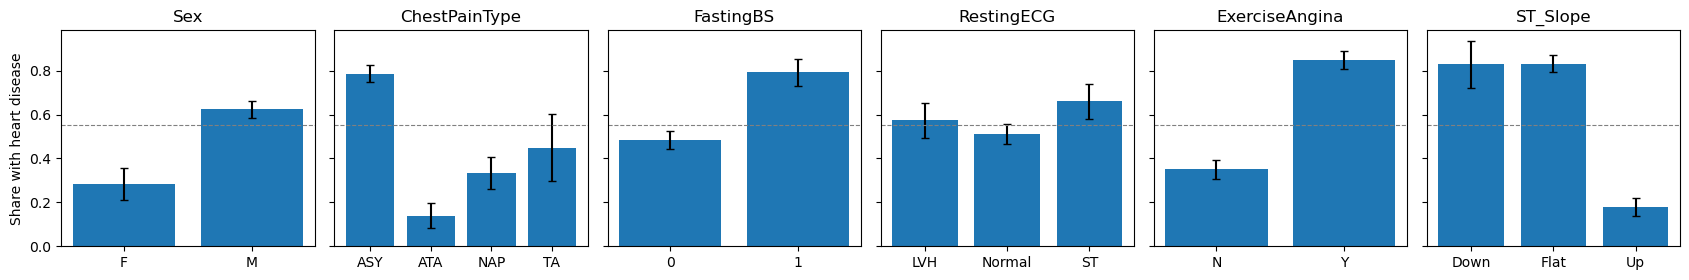

In [11]:
def rate_table(column):
    """The disease rate in each group of a column, the group's size, and how far the rate could be off."""
    table = train.groupby(column)[target].agg(patients="size", disease_rate="mean")
    rate, n = table["disease_rate"], table["patients"]
    table["give_or_take"] = 1.96 * np.sqrt(rate * (1 - rate) / n)
    return table.round(3)

rates = pd.concat({column: rate_table(column) for column in categories}, names=["column", "value"])
print(rates)

fig, axes = plt.subplots(1, 6, figsize=(17, 2.9), sharey=True)
for ax, column in zip(axes, categories):
    table = rates.loc[column]
    ax.bar(table.index.astype(str), table["disease_rate"], yerr=table["give_or_take"], capsize=3)
    ax.axhline(train[target].mean(), color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(column)
axes[0].set_ylabel("Share with heart disease")
plt.tight_layout()
plt.savefig(RESULTS / "disease_rate_in_each_category.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** These categories separate the patients far better than any number did. With an `Up` slope the disease rate is 17.9%, and with a `Flat` one it is 83.2%. With chest pain during exercise it is 84.7%, against 35.0% without. One result looks backwards: patients with no chest pain, `ASY`, have the highest rate, 78.7%. People are sent for a heart examination for a reason, and those who arrive without chest pain were usually sent because of something more serious. Now read the last column. The 45.0% for typical angina rests on 40 patients and could be off by 15 points either way, while the 78.7% for `ASY` rests on 403 patients and is good to 4 points.

<!-- figure: disease_rate_in_each_category.png | Reference plot from the supplied notebook | 2.8cm -->

### Question 12 — A gap against the target

One more column deserves a comparison with the target: the fact that a value is missing. If the patients without a cholesterol reading are like everyone else, the gap is harmless. If they are not, the gap is information.

**Read the code.**

- `isna()` gives `True` where cholesterol is missing, and `.rename(...)` gives that column of `True` and `False` a readable name for the table.
- `pd.crosstab(a, b)` counts the rows for every combination of two columns.
- `~not_measured` flips the mask: `~` means "not".

In [12]:
not_measured = train["Cholesterol"].isna().rename("cholesterol not measured")
print(pd.crosstab(not_measured, train[target]))
print("\ndisease rate when cholesterol was not measured:",
      round(train.loc[not_measured, target].mean(), 3),
      "  when it was:", round(train.loc[~not_measured, target].mean(), 3))

HeartDisease                0    1
cholesterol not measured          
False                     315  290
True                       13  116

disease rate when cholesterol was not measured: 0.899   when it was: 0.479


**What the output shows.** Of the 129 training patients with no cholesterol reading, 116 have heart disease: 89.9%, against 47.9% of the 605 who were measured. The gap is not random. The table joins five hospitals, and the zeros come from the ones that did not record cholesterol and whose patients were sicker. A model should be told that the value was missing, which Question 16 does with a flag column.

**Checkpoint: before you move on**

- Heart rate, age and `Oldpeak` differ between the two groups, while blood pressure and cholesterol hardly do.
- An `Up` ST slope goes with a disease rate of 17.9%, and a `Flat` one with 83.2%.
- The rate for typical angina, 45.0% on 40 patients, could be off by 15 points either way.
- 89.9% of the patients with no cholesterol reading have heart disease, against 47.9% of the rest.

## Part D — Columns against each other

**Goal.** Measure how the number columns move together, and see how the zeros of Part A would have invented a relationship.

*Questions 13–14 · Data: the 734 training patients*

### Question 13 — Correlations, computed twice

A correlation puts one number between −1 and 1 on how two number columns move together along a straight line. Compute the whole table twice, once on the patients as they arrived and once with the zeros marked as missing, and compare the cholesterol column of the two.

**Read the code.**

- `.corr()` computes the correlation of every pair of columns in the table. Blank cells are left out, pair by pair.
- The small DataFrame puts the `Cholesterol` column of both tables side by side.
- `ax.imshow(table, cmap="RdBu_r", vmin=-1, vmax=1)` paints a grid of colours, red for positive and blue for negative. This is a heatmap.
- The two nested `for` loops write each number on top of its cell with `ax.text`, in white where the cell is dark.

              zeros left in  zeros as missing
Age                   -0.10              0.03
RestingBP              0.08              0.10
Cholesterol            1.00              1.00
MaxHR                  0.26              0.00
Oldpeak                0.09              0.06
HeartDisease          -0.24              0.08


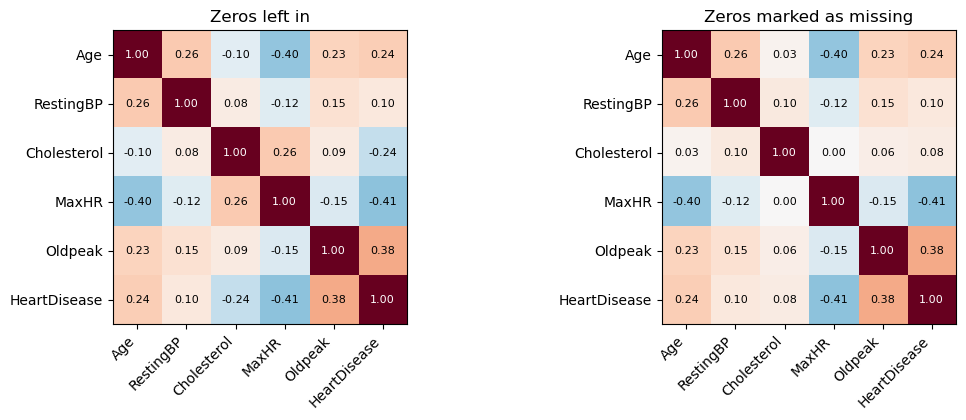

In [13]:
with_zeros = raw_train[numbers + [target]].corr()
as_missing = train[numbers + [target]].corr()
cholesterol_pairs = pd.DataFrame({"zeros left in": with_zeros["Cholesterol"],
                                  "zeros as missing": as_missing["Cholesterol"]}).round(2)
print(cholesterol_pairs)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
panels = [(axes[0], with_zeros, "Zeros left in"), (axes[1], as_missing, "Zeros marked as missing")]
for ax, table, title in panels:
    ax.imshow(table, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(table)), table.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(table)), table.index)
    for i in range(len(table)):
        for j in range(len(table)):
            value = table.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(value) > 0.6 else "black")
    ax.set_title(title)
plt.tight_layout()
plt.savefig(RESULTS / "correlations_with_and_without_the_zeros.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** With the zeros left in, cholesterol has a correlation of −0.24 with heart disease: higher cholesterol, less disease. Mark the zeros as missing and it becomes +0.08, small and in the direction a doctor expects. The correlation of 0.26 with `MaxHR` falls to 0.00. Both relationships were produced by 129 zeros that belong to sick patients and sit at the bottom of the scale. In the repaired table the strongest pairs are `MaxHR` with heart disease (−0.41), age with `MaxHR` (−0.40) and `Oldpeak` with heart disease (0.38). Nothing is near ±0.9, so no column simply repeats another.

<!-- figure: correlations_with_and_without_the_zeros.png | Reference plot from the supplied notebook | 5.6cm -->

### Question 14 — Two numbers and the target on one chart

A scatter plot shows two numbers at once, and colour adds the target. Then draw one chart for all five numbers: put every column on the same scale, stack the columns into one long table with `melt`, and draw a pair of box plots per column.

**Read the code.**

- The first loop draws the two groups one after the other, so that each gets its own colour and legend entry. `s=10` is the size of a dot.
- `standard` holds each value as a number of standard deviations from its column's mean, so that five columns with different units fit on one axis.
- `assign(HeartDisease=...)` adds the target as a column. `melt(id_vars=target, ...)` then turns the five number columns into two: `column`, which names the feature, and `standard units`, which holds the value. 734 rows become 3,670.
- `long.loc[(...) & (...), "standard units"]` selects one feature in one class. The list comprehension collects five such groups, and `boxplot(groups, positions=...)` draws them side by side, shifted left for one class and right for the other.

   HeartDisease column  standard units
0             1    Age        0.969351
1             0    Age        0.121945
2             1    Age        0.545648
rows: 734 patients x 5 columns = 3670


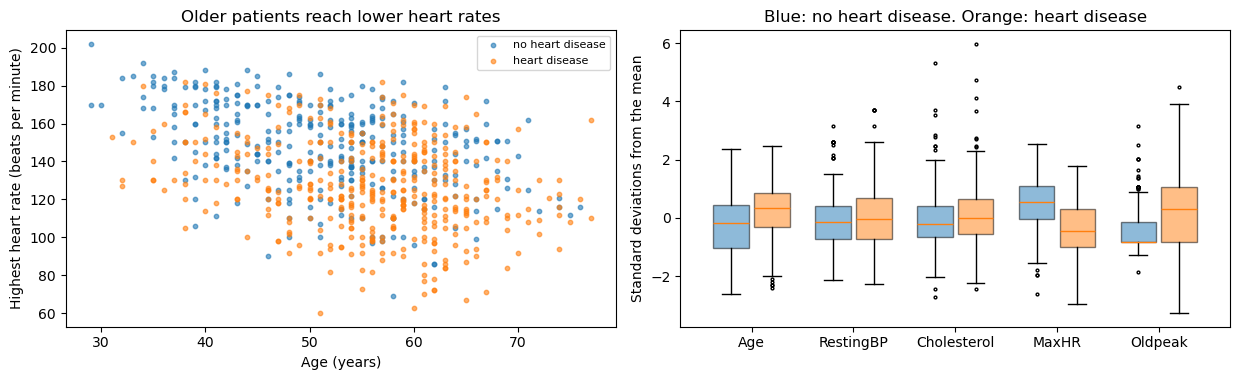

correlation of age with highest heart rate: -0.4


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
for label, name in [(0, "no heart disease"), (1, "heart disease")]:
    group = train[train[target] == label]
    axes[0].scatter(group["Age"], group["MaxHR"], s=10, alpha=0.6, label=name)
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Highest heart rate (beats per minute)")
axes[0].set_title("Older patients reach lower heart rates")
axes[0].legend(fontsize=8)

# melt() stacks the five columns into one long table: one row per patient and column.
standard = (train[numbers] - train[numbers].mean()) / train[numbers].std()
long = standard.assign(HeartDisease=train[target]).melt(
    id_vars=target, var_name="column", value_name="standard units")
print(long.head(3))
print("rows:", len(train), "patients x", len(numbers), "columns =", len(long))

positions = np.arange(len(numbers))
for label, shift, colour in [(0, -0.2, "tab:blue"), (1, 0.2, "tab:orange")]:
    groups = [long.loc[(long["column"] == c) & (long[target] == label), "standard units"].dropna()
              for c in numbers]
    axes[1].boxplot(groups, positions=positions + shift, widths=0.35, patch_artist=True,
                    boxprops={"facecolor": colour, "alpha": 0.5}, flierprops={"markersize": 2})
axes[1].set_xticks(positions, numbers)
axes[1].set_ylabel("Standard deviations from the mean")
axes[1].set_title("Blue: no heart disease. Orange: heart disease")
plt.tight_layout()
plt.savefig(RESULTS / "two_numbers_and_the_target.png", dpi=160, bbox_inches="tight")
plt.show()
print("correlation of age with highest heart rate:", round(train["Age"].corr(train["MaxHR"]), 2))

**What the output shows.** The cloud of the scatter plot slopes downwards: older patients reach lower heart rates, a correlation of −0.40. The orange dots, the patients with heart disease, sit lower and further right. In the second chart the two boxes are furthest apart for `MaxHR` and `Oldpeak` and nearly level for blood pressure and cholesterol, which is the table of Question 10 as a picture.

<!-- figure: two_numbers_and_the_target.png | Reference plot from the supplied notebook | 4.6cm -->

**Checkpoint: before you move on**

- The correlation of cholesterol with heart disease is −0.24 with the zeros left in and +0.08 with the zeros marked as missing.
- No pair of columns is correlated beyond ±0.41, so no column repeats another.
- `melt` turned 734 rows and 5 columns into 3,670 rows.

## Part E — From findings to a first model

**Goal.** Set the bar with two baselines, build a pipeline that carries out the decisions of Parts A to D, and open the test set once.

*Questions 15–17 · Data: the training patients, then the 184 test patients*

### Question 15 — Two baselines that need no fitting

Before fitting anything, set the bar. The first baseline gives every patient the more common answer. The second is one sentence read off the rate table of Question 11: predict heart disease unless the ST slope is `Up`.

**Read the code.**

- `np.ones(len(train), dtype=int)` is an array of 1s, one per training patient: the prediction "disease" for everyone.
- `train["ST_Slope"] != "Up"` is a mask, and `.astype(int)` turns its `True` and `False` into 1 and 0, which makes it a prediction.
- `accuracy_score(truth, prediction)` is the share of patients on whom the two agree.
- The crosstab shows where the rule is right and where it is wrong.

In [15]:
y_train, y_test = train[target], test[target]

always_disease = np.ones(len(train), dtype=int)                    # the majority class, for everyone
one_rule = (train["ST_Slope"] != "Up").astype(int)                 # "disease unless the ST slope is Up"
print("always say disease:", round(accuracy_score(y_train, always_disease), 3))
print("one rule on ST_Slope:", round(accuracy_score(y_train, one_rule), 3))
print(pd.crosstab(train["ST_Slope"], y_train))

always say disease: 0.553
one rule on ST_Slope: 0.827
HeartDisease    0    1
ST_Slope              
Down            8   39
Flat           63  311
Up            257   56


**What the output shows.** Always answering *disease* is right for 55.3% of the training patients. The one-sentence rule is right for 82.7%: of the 313 patients with an `Up` slope, 257 have no disease, and of the 421 others, 350 do. Any model worth building has to beat 82.7%, not 55.3%.

### Question 16 — A pipeline, scored by cross-validation

Now a real model: a logistic regression inside a pipeline that carries out the decisions of the exploration. It fills missing numbers with the median, scales the numbers, and one-hot encodes the six categories. Treat the model itself as a black box for now; the chapter on linear models for classification opens it. Three versions are compared by five-fold cross-validation: the table as it arrived, the zeros marked as missing, and the zeros marked as missing together with a flag column that says so. For each version the cell also prints the weight the model gives to cholesterol.

**Read the code.**

- `SimpleImputer(strategy="median", add_indicator=flag_missing)` fills each blank with its column's median. With `add_indicator=True` it also adds a 0/1 column saying where the blanks were.
- `StandardScaler()` rescales each number column to mean 0 and standard deviation 1, and `OneHotEncoder` turns each category into one 0/1 column per value.
- `ColumnTransformer` applies the number steps to the `numbers` columns and the encoder to the `categories` columns. `Pipeline` chains preparation and model into one object, so whatever is learned is learned from the rows passed to `fit` and from nothing else.
- `StratifiedKFold(5, shuffle=True, random_state=42)` cuts the training patients into five parts. `cross_val_score` fits on four of them and scores on the fifth, five times, and returns the five scores.
- `fitted.named_steps["model"].coef_[0]` holds one weight per prepared column and `get_feature_names_out()` their names. `filter(like="Cholesterol")` keeps the cholesterol ones.

In [16]:
def make_model(flag_missing):
    """Fill gaps with the median, scale the numbers, one-hot encode the categories, fit the model."""
    number_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=flag_missing)),
        ("scale", StandardScaler()),
    ])
    prepare = ColumnTransformer([
        ("num", number_steps, numbers),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categories),
    ])
    return Pipeline([("prepare", prepare), ("model", LogisticRegression(max_iter=2000))])

folds = StratifiedKFold(5, shuffle=True, random_state=42)
versions = {
    "zeros left in": (raw_train, False),
    "zeros as missing": (train, False),
    "zeros as missing + flag": (train, True),
}
comparison = []
for name, (table, flag_missing) in versions.items():
    X = table[numbers + categories]
    accuracy = cross_val_score(make_model(flag_missing), X, y_train, cv=folds, scoring="accuracy")
    auc = cross_val_score(make_model(flag_missing), X, y_train, cv=folds, scoring="roc_auc")
    fitted = make_model(flag_missing).fit(X, y_train)
    weights = pd.Series(fitted.named_steps["model"].coef_[0],
                        index=fitted.named_steps["prepare"].get_feature_names_out())
    cholesterol = weights.filter(like="Cholesterol").rename(lambda name: name.replace("num__", ""))
    comparison.append({"version": name, "accuracy": accuracy.mean(), "spread": accuracy.std(),
                       "roc_auc": auc.mean()})
    print(f"{name:24s} accuracy {accuracy.mean():.3f} (+/- {accuracy.std():.3f})  "
          f"ROC AUC {auc.mean():.3f}  {cholesterol.round(2).to_dict()}")

zeros left in            accuracy 0.853 (+/- 0.041)  ROC AUC 0.925  {'Cholesterol': -0.49}


zeros as missing         accuracy 0.847 (+/- 0.030)  ROC AUC 0.922  {'Cholesterol': 0.05}


zeros as missing + flag  accuracy 0.857 (+/- 0.039)  ROC AUC 0.928  {'Cholesterol': 0.04, 'missingindicator_Cholesterol': 0.71}


**What the output shows.** All three versions score about 85%, three points above the one-sentence rule. Their accuracies differ by one point, well inside the spread of three to four points between folds, so the score cannot tell them apart. The weights can. With the zeros left in, cholesterol gets a weight of −0.49: the model has learned that low cholesterol predicts heart disease, because zero is the lowest value there is. With the zeros marked as missing and a flag added, the weight on cholesterol itself is 0.04 and the flag carries 0.71: *not having been measured* is what goes with the disease. The first model scores as well and has learned something false, and it would fail at any hospital that measures every patient.

### Question 17 — Open the test set, once

The procedure is chosen: zeros as missing, with a flag. Fit it on all 734 training patients and open the test set once. Report accuracy, ROC AUC and the confusion matrix, and, because the exploration found that four patients in five are men, report the two sexes separately.

**Read the code.**

- `predict_proba(...)[:, 1]` is the model's probability of heart disease for each test patient. Column 0 would be the probability of no disease.
- `chance >= 0.5` turns the probabilities into yes or no answers at a threshold of one half.
- `confusion_matrix(truth, prediction)` counts the four outcomes. Its rows are the truth and its columns the prediction.
- `roc_auc_score` takes the probabilities, not the yes or no answers, because it measures how well the model ranks patients.
- `(test["Sex"] == sex).to_numpy()` is a mask as a plain array, used to pick the matching entries of `y_test` and `predicted`.

In [17]:
final = make_model(flag_missing=True).fit(train[numbers + categories], y_train)
chance = final.predict_proba(test[numbers + categories])[:, 1]      # probability of heart disease
predicted = (chance >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, predicted)
test_auc = roc_auc_score(y_test, chance)
matrix = confusion_matrix(y_test, predicted)
print("test accuracy:", round(test_accuracy, 3), "  test ROC AUC:", round(test_auc, 3))
print(pd.DataFrame(matrix, index=["no disease", "disease"], columns=["predicted no", "predicted yes"]))

# The exploration found that men are four patients in five, so report the two groups separately.
for sex, name in [("M", "men"), ("F", "women")]:
    rows = (test["Sex"] == sex).to_numpy()
    group_accuracy = accuracy_score(y_test[rows], predicted[rows])
    print(f"{name:6s} {rows.sum():3d} test patients  accuracy {group_accuracy:.3f}  "
          f"disease rate {y_test[rows].mean():.3f}")

test accuracy: 0.897   test ROC AUC: 0.932
            predicted no  predicted yes
no disease            71             11
disease                8             94
men    146 test patients  accuracy 0.890  disease rate 0.658
women   38 test patients  accuracy 0.921  disease rate 0.158


**What the output shows.** The model is right for 165 of the 184 test patients, 89.7%, with a ROC AUC of 0.932. It raises 11 false alarms among the 82 healthy patients and misses 8 of the 102 who have the disease. By sex it scores 89.0% on 146 men and 92.1% on 38 women. Do not read much into that gap. Thirty-eight patients is a small group, and only 15.8% of the women in the test set have the disease, so always answering *no disease* would already score 84.2% on them. A result for a small group needs its count and its own baseline beside it.

**Checkpoint: before you move on**

- The bar to beat: 55.3% for always answering disease, and 82.7% for one rule on the ST slope.
- The three pipelines score 0.853, 0.847 and 0.857, but only the last gives cholesterol a believable weight.
- On the sealed test set: accuracy 0.897, ROC AUC 0.932, 11 false alarms and 8 misses.

## Finish — Save the evidence, then try it yourself

**Goal.** Write the results folder and the exploration log, then extend the examination yourself before reading one worked solution.

*Questions 18–20*

### Question 18 — Save the evidence

Write the tables to the results folder, together with the exploration log: each thing you saw, and what the pipeline does about it. These files are regenerated on every run, so do not edit them by hand.

**Read the code.**

- `to_csv(path)` writes a table to a file. `index=False` leaves out the row labels when they carry no information.
- `pd.Series(cleaning_log, name="count")` turns the dictionary of Question 5 into a column, so that it can be saved.
- The exploration log is built from a list of tuples, one per finding, with the column names given once.
- `RESULTS.iterdir()` lists the files in the folder, and `sorted(...)` puts their names in order.

In [18]:
overview.to_csv(RESULTS / "column_overview.csv")
pd.Series(cleaning_log, name="count").rename_axis("step").to_csv(RESULTS / "cleaning_log.csv")
summaries.round(2).to_csv(RESULTS / "five_number_summaries.csv")
rates.to_csv(RESULTS / "disease_rate_by_category.csv")
cholesterol_pairs.to_csv(RESULTS / "cholesterol_correlations.csv")
pd.DataFrame(comparison).round(3).to_csv(RESULTS / "model_comparison.csv", index=False)
metrics = pd.DataFrame([{
    "test_accuracy": test_accuracy, "test_roc_auc": test_auc,
    "true_negatives": matrix[0, 0], "false_alarms": matrix[0, 1],
    "misses": matrix[1, 0], "true_positives": matrix[1, 1],
}])
metrics.round(3).to_csv(RESULTS / "metrics.csv", index=False)

# The exploration log: what was seen, and what the pipeline does about it.
exploration_log = pd.DataFrame([
    ("two columns hold zeros that mean 'not measured'", "mark as missing", "before the split"),
    ("the cholesterol gap goes with the disease", "fill with the median, add a flag", "pipeline"),
    ("FastingBS is 0/1", "treat as a category", "pipeline"),
    ("cholesterol and Oldpeak are right-skewed, with extremes", "keep every patient, scale", "pipeline"),
    ("categories separate the patients better than numbers", "one-hot encode all six", "pipeline"),
    ("typical angina has only 40 training patients", "keep it, read its effect with caution", "report"),
    ("men are four patients in five", "report results for women separately", "evaluation"),
], columns=["observation", "decision", "where"])
exploration_log.to_csv(RESULTS / "exploration_log.csv", index=False)
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['box_plots_of_the_number_columns.png', 'cholesterol_before_and_after.png', 'cholesterol_correlations.csv', 'cleaning_log.csv', 'column_overview.csv', 'correlations_with_and_without_the_zeros.png', 'disease_rate_by_category.csv', 'disease_rate_in_each_category.png', 'exploration_log.csv', 'five_number_summaries.csv', 'how_often_each_category_occurs.png', 'metrics.csv', 'model_comparison.csv', 'numbers_against_the_target.png', 'the_shape_of_each_number_column.png', 'two_numbers_and_the_target.png']


**What the output shows.** Sixteen files: eight figures and eight tables. Open `exploration_log.csv`: it is the examination of this table on one page, and the pipeline of Question 16 does exactly what it says.

## Try it yourself

The exploration found that men are four patients in five, so every rate so far is mostly a rate for men. First, compute the disease rate by chest pain type separately for women and for men, with the number of patients in each group. Second, `Oldpeak` is exactly 0 for 41.4% of the training patients: add a column `any_drop`, which is 1 when `Oldpeak` is above 0, and check whether it improves the cross-validated accuracy of Question 16.

Attempt it in the cell below before reading the solution.

### Question 19 — Try it yourself

In [19]:
# Your work here

### One solution

The rate table once per sex, then the pipeline of Question 16 with one more number column.

### Question 20 — One solution

The rate table once per sex, then the pipeline of Question 16 with one more number column.

**Read the code.**

- `train[train["Sex"] == sex]` keeps the patients of one sex, and the same `groupby(...).agg(...)` as in Question 11 then runs on that smaller table.
- `table.assign(any_drop=...)` returns a copy of the table with one more column and leaves `train` itself unchanged.
- `make_model_with(extra)` is the pipeline of Question 16 with the list of number columns made longer by `extra`.

In [20]:
# Part 1: the same rate table, once for women and once for men.
for sex, name in [("F", "women"), ("M", "men")]:
    group = train[train["Sex"] == sex]
    table = group.groupby("ChestPainType")[target].agg(patients="size", disease_rate="mean").round(3)
    print(name, "- overall disease rate", round(group[target].mean(), 3))
    print(table, "\n")

# Part 2: split Oldpeak into "was there any drop?" and keep the size, then score the model again.
def with_drop_flag(table):
    return table.assign(any_drop=(table["Oldpeak"] > 0).astype(int))

def make_model_with(extra):
    number_steps = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                             ("scale", StandardScaler())])
    prepare = ColumnTransformer([("num", number_steps, numbers + extra),
                                 ("cat", OneHotEncoder(handle_unknown="ignore"), categories)])
    return Pipeline([("prepare", prepare), ("model", LogisticRegression(max_iter=2000))])

candidates = [("as in Question 16", [], train),
              ("with any_drop added", ["any_drop"], with_drop_flag(train))]
for label, extra, table in candidates:
    X = table[numbers + extra + categories]
    scores = cross_val_score(make_model_with(extra), X, y_train, cv=folds, scoring="accuracy")
    print(f"{label:22s} accuracy {scores.mean():.3f} (+/- {scores.std():.3f})")
print("disease rate with no drop:", round(train.loc[train["Oldpeak"] <= 0, target].mean(), 3),
      "  with a drop:", round(train.loc[train["Oldpeak"] > 0, target].mean(), 3))

women - overall disease rate 0.284
               patients  disease_rate
ChestPainType                        
ASY                  59         0.576
ATA                  47         0.085
NAP                  40         0.125
TA                    9         0.111 

men - overall disease rate 0.625
               patients  disease_rate
ChestPainType                        
ASY                 344         0.823
ATA                  89         0.169
NAP                 115         0.409
TA                   31         0.548 

as in Question 16      accuracy 0.857 (+/- 0.039)


with any_drop added    accuracy 0.858 (+/- 0.032)
disease rate with no drop: 0.361   with a drop: 0.699


**What it shows.** Women have a much lower disease rate than men, 28.4% against 62.5%, and the order of the chest pain types is the same for both: no chest pain is the worst sign. But the women's table rests on small groups. Nine women have typical angina and one of them has the disease, so the 11.1% printed there means almost nothing. The new column carries real signal, a disease rate of 69.9% with a drop against 36.1% without, yet the cross-validated accuracy only moves from 0.857 to 0.858. The model already had `Oldpeak` itself and the ST slope, which say much the same thing. A feature can be informative and still add nothing, which is why the test is always the model's validation score.